# 02 — Customer Segmentation (RFM + K-Means)

**Goal:** Build RFM-style features and cluster customers with K-Means, choosing k with the
Elbow method and the Silhouette score.

**RFM proxies** (the dataset has no transaction log, so we use proxies):
- **Recency** -> `tenure` (months as a customer)
- **Frequency** -> number of subscribed services
- **Monetary** -> `MonthlyCharges`

**Outputs:**
- `../data/processed/telco_segmented.csv`
- `../results/figures/elbow_silhouette.png`
- `../results/tables/segment_profiles.csv`


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

SEED = 42
np.random.seed(SEED)
sns.set_style('whitegrid')
NAVY, BLUE, TEAL, CORAL = '#0A2540', '#1C7293', '#00A896', '#F4845F'

df = pd.read_csv('../data/processed/telco_clean.csv')
print(f'Loaded: {df.shape}')


Loaded: (7032, 23)


## 1. Build RFM-style features

In [2]:
service_cols = ['PhoneService','MultipleLines','InternetService','OnlineSecurity',
                'OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies']

def count_services(row):
    # Count only services the customer actually subscribes to
    return sum(1 for c in service_cols
               if row[c] not in ['No', 'No phone service', 'No internet service'])

df['NumServices'] = df.apply(count_services, axis=1)

# Assemble RFM matrix
rfm = df[['tenure', 'NumServices', 'MonthlyCharges']].copy()
rfm.columns = ['Recency', 'Frequency', 'Monetary']
print(rfm.describe().round(2))


       Recency  Frequency  Monetary
count  7032.00    7032.00   7032.00
mean     32.42       4.15     64.80
std      24.55       2.31     30.09
min       1.00       1.00     18.25
25%       9.00       2.00     35.59
50%      29.00       4.00     70.35
75%      55.00       6.00     89.86
max      72.00       9.00    118.75


## 2. Scale the features

K-Means uses Euclidean distance, so features on different scales must be standardised
(mean 0, standard deviation 1). Otherwise `MonthlyCharges` would dominate `NumServices`.

In [3]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm)
print('Scaled shape:', rfm_scaled.shape)


Scaled shape: (7032, 3)


## 3. Choose k — Elbow method and Silhouette score

We test k from 2 to 6. The Elbow method looks for where the inertia (within-cluster sum of
squares) stops dropping sharply. The Silhouette score measures how well-separated the clusters
are (higher is better).

In [4]:
ks = range(2, 7)
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, random_state=SEED, n_init=10)
    labels = km.fit_predict(rfm_scaled)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(rfm_scaled, labels))

for k, i, s in zip(ks, inertias, silhouettes):
    print(f'k={k}  inertia={i:>9.1f}  silhouette={s:.4f}')


k=2  inertia=  10494.8  silhouette=0.4217
k=3  inertia=   6652.5  silhouette=0.4200
k=4  inertia=   4949.2  silhouette=0.4266
k=5  inertia=   4031.3  silhouette=0.3849
k=6  inertia=   3202.2  silhouette=0.4011


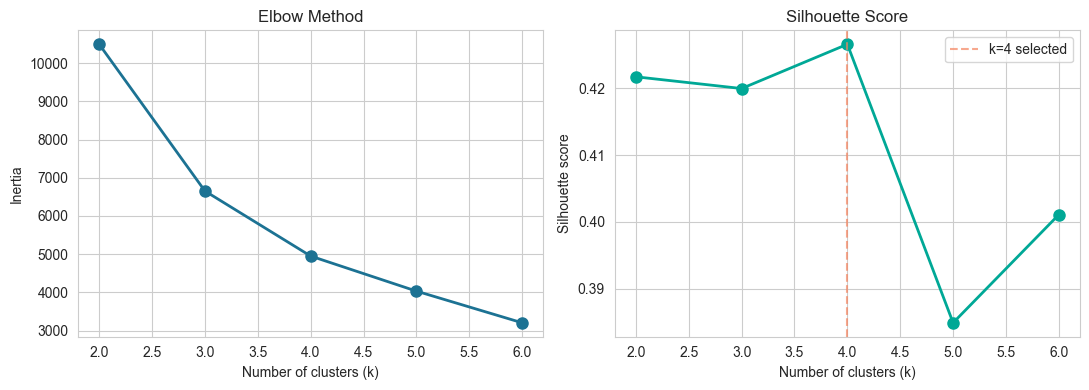

In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))

ax1.plot(list(ks), inertias, 'o-', color=BLUE, linewidth=2, markersize=8)
ax1.set_xlabel('Number of clusters (k)'); ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method')

ax2.plot(list(ks), silhouettes, 'o-', color=TEAL, linewidth=2, markersize=8)
ax2.axvline(4, color=CORAL, linestyle='--', alpha=0.7, label='k=4 selected')
ax2.set_xlabel('Number of clusters (k)'); ax2.set_ylabel('Silhouette score')
ax2.set_title('Silhouette Score'); ax2.legend()

plt.tight_layout()
plt.savefig('../results/figures/elbow_silhouette.png', dpi=200, bbox_inches='tight')
plt.show()


## 4. Fit final K-Means (k=4)

k=4 gives the highest Silhouette score (~0.427) and produces four business-interpretable
segments.

In [6]:
K = 4
kmeans = KMeans(n_clusters=K, random_state=SEED, n_init=10)
df['Segment'] = kmeans.fit_predict(rfm_scaled)

profile = df.groupby('Segment').agg(
    Customers=('customerID', 'count'),
    AvgTenure=('tenure', 'mean'),
    AvgServices=('NumServices', 'mean'),
    AvgMonthly=('MonthlyCharges', 'mean'),
    ChurnRate=('ChurnBinary', 'mean')
).round(2)
profile['ChurnRate'] = (profile['ChurnRate']*100).round(1)
print(profile)


         Customers  AvgTenure  AvgServices  AvgMonthly  ChurnRate
Segment                                                          
0             2156      57.39         6.72       91.30       16.0
1             1498      10.28         1.65       29.17       24.0
2             2406      14.93         4.24       77.24       47.0
3              972      54.47         2.06       30.13        4.0


## 5. Interpret and name the segments

Give each numeric cluster a human-readable label based on its profile. **Note:** cluster numbers
can differ between runs on different machines — always name segments by their *characteristics*,
not by their number.

In [7]:
# Inspect the profile above, then map each segment to a descriptive name.
# Adjust the mapping if your cluster numbers differ.
segment_names = {
    0: 'Premium Loyal',       # long tenure, many services, high spend, low churn
    1: 'New Low-Spend',       # short tenure, few services, low spend
    2: 'At-Risk High-Spend',  # short-mid tenure, high spend, very high churn
    3: 'Long-term Minimal',   # long tenure, few services, very low churn
}
df['SegmentName'] = df['Segment'].map(segment_names)
print(df.groupby('SegmentName')['ChurnBinary'].agg(['count', 'mean']).round(3))


                    count   mean
SegmentName                     
At-Risk High-Spend   2406  0.470
Long-term Minimal     972  0.041
New Low-Spend        1498  0.240
Premium Loyal        2156  0.156


## 6. Save

In [8]:
profile.to_csv('../results/tables/segment_profiles.csv')
df.to_csv('../data/processed/telco_segmented.csv', index=False)
print('Saved: segment_profiles.csv, telco_segmented.csv, elbow_silhouette.png')


Saved: segment_profiles.csv, telco_segmented.csv, elbow_silhouette.png
